# Архитектура LLM II · почему attention дорогой
**МФТИ / girafe-ai · PyTorch, оценки стоимости, проверяемые гипотезы**

Почему ответ на длинный промпт начинается с паузы, а потом токены идут быстро?
Куда уходит память GPU, когда контекст растёт до 128K токенов?
Что общего у KV-cache, GQA, MLA, sliding window и Mamba?

В этом ноутбуке вы посчитаете FLOPs и память attention, реализуете KV-cache, GQA, сжатие кэша как в MLA,
sliding window и sparse attention, рекуррентную альтернативу attention (DeltaNet),
а в конце разберёте конфиги двух реальных моделей: **DeepSeek-V3** и **Qwen3.8-Flash-Next**.

**Связь с курсом:** в прошлом ноутбуке мы собрали маленький decoder и проверили, что он не подсматривает в будущее.
Теперь спросим, что происходит, когда такой decoder работает на длинном контексте. Следующая тема — MoE и сложные архитектуры.

| Раздел | Вопрос блока |
|---|---|
| 1. Стоимость attention | Как растут FLOPs и память с длиной контекста? |
| 2. Генерация и KV-cache | Почему генерация упирается в память, а не в вычисления? |
| 3. MQA, GQA, MLA | Как уменьшить кэш, не выбрасывая контекст? |
| 4. Sliding window и sparse attention | Обязательно ли смотреть на все токены? |
| 5. Архитектура или реализация | Что меняет функцию модели, а что только скорость? |
| 6. Линейное внимание, SSM, Mamba | Можно ли хранить контекст в состоянии фиксированного размера? |
| 7. Разбор: DeepSeek-V3 и Qwen3.8-Flash-Next | Как это устроено в настоящих моделях? |

Обозначения те же, что в первом ноутбуке: $B$ — batch, $T$ — длина, $d$ — ширина, $H$ — число голов,
$d_h$ — ширина головы, $N$ — число блоков. Новые: $H_{kv}$ — число голов для ключей и значений,
$r$ — ранг сжатого кэша в MLA, $W$ — размер окна, $k$ — бюджет sparse attention.

Код уже написан: запускайте ячейки и меняйте отдельные числа. Перед каждой проверкой сначала предскажите результат.

### Как запустить
1. Откройте ноутбук в Jupyter / VS Code / Colab и выберите Python-ядро.
2. Нужны `torch`, `numpy`, `matplotlib`. Если их нет: `%pip install torch numpy matplotlib`.
3. Выполните **Restart Kernel → Run All**. Обучения здесь нет, весь ноутбук считается на CPU примерно за минуту.

Замеры времени зависят от вашего компьютера: смотрите на **отношения** чисел, а не на абсолютные значения.

In [1]:
import math
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
torch.set_num_threads(2)
plt.rcParams.update({"figure.figsize": (9, 3.5), "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
print("PyTorch:", torch.__version__)


def fmt_bytes(n):
    """Человекочитаемый размер: 1 KiB = 1024 байт."""
    for unit in ["B", "KiB", "MiB", "GiB", "TiB"]:
        if abs(n) < 1024 or unit == "TiB":
            return f"{n:,.1f} {unit}"
        n /= 1024


def heatmap(ax, matrix, title, xlabel="Ключ j", ylabel="Запрос i", **kwargs):
    if isinstance(matrix, torch.Tensor):
        matrix = matrix.detach().cpu().float().numpy()
    image = ax.imshow(matrix, aspect="auto", **kwargs)
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
    return image


def attention(q, k, v, causal=True):
    """q: [..., Tq, d], k, v: [..., Tk, d]. Если Tq < Tk, запросы — последние Tq позиций."""
    scores = (q @ k.transpose(-2, -1)) / math.sqrt(q.shape[-1])
    if causal:
        tq, tk = q.shape[-2], k.shape[-2]
        allowed = torch.ones(tq, tk, dtype=torch.bool, device=q.device).tril(diagonal=tk - tq)
        scores = scores.masked_fill(~allowed, float("-inf"))
    weights = scores.softmax(dim=-1)
    return weights @ v, weights


def apply_rope(z, positions):
    """RoPE из первого ноутбука. z: [..., T, d_h], positions: [T]."""
    width = z.shape[-1]
    frequencies = 10000.0 ** (-torch.arange(0, width, 2, device=z.device).float() / width)
    angles = positions.float()[:, None] * frequencies[None, :]
    cosine, sine = angles.cos().to(z.dtype), angles.sin().to(z.dtype)
    even, odd = z[..., 0::2], z[..., 1::2]
    return torch.stack((even * cosine - odd * sine, even * sine + odd * cosine), dim=-1).flatten(-2)

PyTorch: 2.5.1


## 1 · Сколько стоит attention
**Зачем:** прежде чем ускорять, нужно понять, что именно дорого.

Считаем одно умножение-сложение за 2 FLOPs. Для одного блока с шириной $d$ на последовательности длины $T$:

| Часть | FLOPs | Как растёт с $T$ |
|---|---|---|
| Проекции $Q, K, V, O$ (MHA) | $\approx 8Td^2$ | линейно |
| $QK^\top$ и $AV_a$ | $\approx 4T^2d$ | **квадратично** |
| SwiGLU MLP, $d_{ff}\approx 8d/3$ | $\approx 16Td^2$ | линейно |

Квадратичная часть обгоняет все линейные, когда $4T^2d > 24Td^2$, то есть при $T > 6d$.
Для $d=4096$ это примерно 24 тысячи токенов: на коротких промптах дороже всего матрицы весов, на длинных — сам attention.

Вторая проблема — **память**. Если честно построить матрицу scores, в ней $B\cdot H\cdot T^2$ чисел.

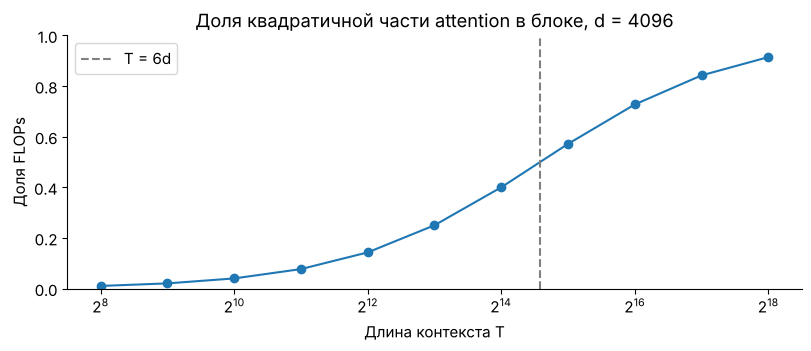

Память на матрицу scores одного слоя (H = 32, fp16, B = 1):
  T =   4,096: 1.0 GiB
  T =  32,768: 64.0 GiB
  T = 131,072: 1.0 TiB


In [2]:
def block_flops(T, d):
    projections = 8 * T * d**2
    attention_quadratic = 4 * T**2 * d
    mlp = 16 * T * d**2
    return projections, attention_quadratic, mlp


d_model = 4096
lengths = np.array([2**p for p in range(8, 19)])  # от 256 до 262144
shares = []
for T in lengths:
    proj, quad, mlp = block_flops(int(T), d_model)
    shares.append(quad / (proj + quad + mlp))

fig, ax = plt.subplots(figsize=(8, 3.4), constrained_layout=True)
ax.semilogx(lengths, shares, marker="o", base=2)
ax.axvline(6 * d_model, color="gray", linestyle="--", label="T = 6d")
ax.set(xlabel="Длина контекста T", ylabel="Доля FLOPs", ylim=(0, 1),
       title=f"Доля квадратичной части attention в блоке, d = {d_model}")
ax.legend()
plt.show()

print("Память на матрицу scores одного слоя (H = 32, fp16, B = 1):")
for T in [4_096, 32_768, 131_072]:
    print(f"  T = {T:>7,}: {fmt_bytes(32 * T * T * 2)}")

Теперь проверим квадратичный рост на практике: замерим время явного attention на CPU.

In [3]:
def time_attention(T, heads=4, head_dim=64, repeats=3):
    q, k, v = [torch.randn(1, heads, T, head_dim) for _ in range(3)]
    attention(q, k, v)  # прогрев
    start = time.perf_counter()
    for _ in range(repeats):
        attention(q, k, v)
    return (time.perf_counter() - start) / repeats


timings = {T: time_attention(T) for T in [256, 512, 1024, 2048]}
previous = None
for T, seconds in timings.items():
    ratio = "" if previous is None else f" | ×{seconds / previous:.1f} к предыдущему"
    print(f"T = {T:>5}: {seconds * 1000:7.1f} мс{ratio}")
    previous = seconds

T =   256:     1.0 мс
T =   512:     7.0 мс | ×6.7 к предыдущему
T =  1024:    26.9 мс | ×3.8 к предыдущему
T =  2048:   118.1 мс | ×4.4 к предыдущему


**Вопрос 1.** Во сколько раз растёт время attention при удвоении $T$? А время MLP? Почему на промптах в пару тысяч токенов attention — не главная статья расходов?

## 2 · Генерация и KV-cache
**Зачем:** обучение и генерация нагружают модель по-разному.

Генерация состоит из двух фаз:
- **Prefill** — весь промпт обрабатывается за один параллельный проход, как при обучении. Это и есть «пауза перед первым токеном».
- **Decode** — дальше модель выдаёт по одному токену, и каждый новый токен — отдельный проход.

Из первого ноутбука мы знаем: при causal mask выходы префикса не зависят от будущего.
Значит, ключи и значения прошлых токенов **не меняются**, когда приходят новые. Их можно посчитать один раз и сохранить.
Это и есть **KV-cache**: на шаге decode считаем $q, k, v$ только для нового токена, а $K, V$ прошлых берём из кэша.

Размер кэша на одну последовательность:

$$\text{KV bytes} = 2 \cdot N \cdot H_{kv} \cdot d_h \cdot T \cdot \text{bytes}.$$

Множитель 2 — это $K$ и $V$, bytes = 2 для bf16. Пока $H_{kv} = H$; в следующем разделе это изменится.

Ниже слой attention, который умеет работать с кэшем. Обратите внимание: RoPE применяется к ключу **до** записи в кэш,
поэтому в кэше лежат уже повёрнутые ключи, а новый запрос поворачивается на свою абсолютную позицию.

In [4]:
class CausalSelfAttention(nn.Module):
    """MHA при kv_heads == heads, GQA при 1 < kv_heads < heads, MQA при kv_heads == 1."""

    def __init__(self, width, heads, kv_heads=None):
        super().__init__()
        kv_heads = kv_heads or heads
        assert width % heads == 0 and heads % kv_heads == 0
        self.heads, self.kv_heads, self.head_dim = heads, kv_heads, width // heads
        self.query = nn.Linear(width, heads * self.head_dim, bias=False)
        self.key = nn.Linear(width, kv_heads * self.head_dim, bias=False)
        self.value = nn.Linear(width, kv_heads * self.head_dim, bias=False)
        self.out = nn.Linear(heads * self.head_dim, width, bias=False)

    def forward(self, x, cache=None):
        batch, length, _ = x.shape
        q = self.query(x).view(batch, length, self.heads, self.head_dim).transpose(1, 2)
        k = self.key(x).view(batch, length, self.kv_heads, self.head_dim).transpose(1, 2)
        v = self.value(x).view(batch, length, self.kv_heads, self.head_dim).transpose(1, 2)

        offset = 0 if cache is None or cache.get("k") is None else cache["k"].shape[-2]
        positions = torch.arange(offset, offset + length)
        q, k = apply_rope(q, positions), apply_rope(k, positions)
        if cache is not None:
            if cache.get("k") is not None:
                k = torch.cat([cache["k"], k], dim=-2)
                v = torch.cat([cache["v"], v], dim=-2)
            cache["k"], cache["v"] = k, v

        group = self.heads // self.kv_heads  # сколько голов запросов делят одну голову K/V
        k, v = k.repeat_interleave(group, dim=1), v.repeat_interleave(group, dim=1)
        result, _ = attention(q, k, v, causal=True)
        return self.out(result.transpose(1, 2).reshape(batch, length, -1))


torch.manual_seed(0)
layer = CausalSelfAttention(width=64, heads=8).eval()
sequence = torch.randn(1, 12, 64)

with torch.no_grad():
    full = layer(sequence)                       # всё за один проход
    cache = {}
    pieces = [layer(sequence[:, :5], cache)]      # prefill: первые 5 токенов
    for t in range(5, 12):                        # decode: по одному токену
        pieces.append(layer(sequence[:, t:t + 1], cache))
    incremental = torch.cat(pieces, dim=1)

torch.testing.assert_close(full, incremental, atol=1e-5, rtol=1e-5)
print("Prefill + decode с кэшем дают те же выходы, что и полный проход.")
print("Форма кэша K:", tuple(cache["k"].shape), "= [B, H_kv, T, d_h]")

Prefill + decode с кэшем дают те же выходы, что и полный проход.
Форма кэша K: (1, 8, 12, 8) = [B, H_kv, T, d_h]


Сравним генерацию с кэшем и без него. Без кэша на каждом шаге пересчитываем весь префикс.

In [5]:
def generate_steps(layer, prompt, steps, use_cache):
    x = prompt
    cache = {} if use_cache else None
    with torch.no_grad():
        if use_cache:
            out = layer(x, cache)
        for _ in range(steps):
            if use_cache:
                new = out[:, -1:]           # «следующий токен» — просто последний выход
                out = layer(new, cache)
                x = torch.cat([x, new], dim=1)
            else:
                out = layer(x)
                x = torch.cat([x, out[:, -1:]], dim=1)
    return x


torch.manual_seed(1)
big_layer = CausalSelfAttention(width=256, heads=8).eval()
prompt = torch.randn(1, 64, 256)
for use_cache in [False, True]:
    start = time.perf_counter()
    generate_steps(big_layer, prompt, steps=300, use_cache=use_cache)
    label = "с кэшем  " if use_cache else "без кэша "
    print(f"{label}: {time.perf_counter() - start:.2f} с на 300 шагов")

без кэша : 0.81 с на 300 шагов
с кэшем  : 0.14 с на 300 шагов


### Почему decode упирается в память
На шаге decode новый запрос один, а прочитать нужно весь кэш. На каждый прочитанный байт приходится всего несколько FLOPs.
У современных GPU отношение «FLOPs в секунду / байт в секунду» — сотни, поэтому вычислительные блоки простаивают в ожидании памяти.
Отсюда практическое правило: **скорость decode определяется тем, сколько байт нужно прочитать за шаг** — веса плюс KV-cache.

Посчитаем кэш для конфигурации в духе Llama-3-8B: $N=32$, $H=32$, $H_{kv}=8$, $d_h=128$, bf16.

In [6]:
def kv_cache_bytes(layers, kv_heads, head_dim, tokens, batch=1, bytes_per=2):
    return 2 * layers * kv_heads * head_dim * tokens * batch * bytes_per


llama_like = dict(layers=32, kv_heads=8, head_dim=128)
per_token = kv_cache_bytes(**llama_like, tokens=1)
print("На один токен:", fmt_bytes(per_token))
for tokens in [8_192, 131_072]:
    print(f"Контекст {tokens:>7,}: {fmt_bytes(kv_cache_bytes(**llama_like, tokens=tokens))}")
print("Для сравнения, веса 8B модели в bf16:", fmt_bytes(8e9 * 2))

На один токен: 128.0 KiB
Контекст   8,192: 1.0 GiB
Контекст 131,072: 16.0 GiB
Для сравнения, веса 8B модели в bf16: 14.9 GiB


**Вопрос 2.** Почему кэшируют $K$ и $V$, но не $Q$? Нужен ли KV-cache encoder-only модели, которая классифицирует текст за один проход?

**Вопрос 3.** Сервер одновременно ведёт 32 диалога по 8 192 токена на модели из ячейки выше. Сколько памяти займёт KV-cache? Сравните с весами.

## 3 · MQA, GQA и MLA: как уменьшить кэш
**Зачем:** кэш растёт как $N \cdot H_{kv} \cdot d_h \cdot T$. Длину $T$ уменьшать не хочется, значит, уменьшаем остальное.

### MQA и GQA
- **MHA**: у каждой головы запросов свои $K$ и $V$, $H_{kv}=H$.
- **MQA** (Multi-Query Attention): одна голова $K, V$ на все головы запросов, $H_{kv}=1$. Кэш меньше в $H$ раз, но качество обычно падает.
- **GQA** (Grouped-Query Attention): головы запросов делятся на $H_{kv}$ групп, у каждой группы свои $K, V$. Компромисс, который сейчас используют почти все открытые модели.

Слой из раздела 2 уже поддерживает GQA через `repeat_interleave`. Проверим полезный факт:
**GQA — это MHA, у которой веса $K, V$ внутри группы просто совпадают**.

In [7]:
torch.manual_seed(2)
gqa = CausalSelfAttention(width=64, heads=8, kv_heads=2).eval()
mha = CausalSelfAttention(width=64, heads=8, kv_heads=8).eval()
group = 8 // 2
with torch.no_grad():
    mha.query.weight.copy_(gqa.query.weight)
    mha.out.weight.copy_(gqa.out.weight)
    for name in ["key", "value"]:
        w = getattr(gqa, name).weight.view(2, 8, 64)                 # [H_kv, d_h, d]
        getattr(mha, name).weight.copy_(w.repeat_interleave(group, dim=0).reshape(64, 64))
    torch.testing.assert_close(gqa(sequence), mha(sequence), atol=1e-5, rtol=1e-5)
print("GQA совпала с MHA, у которой K/V-веса продублированы внутри групп.")

print("\nKV-cache на токен для N=32, H=32, d_h=128:")
for name, kv_heads in [("MHA", 32), ("GQA-8", 8), ("MQA", 1)]:
    print(f"  {name:6s} H_kv = {kv_heads:2d}: {fmt_bytes(kv_cache_bytes(32, kv_heads, 128, 1))}")

GQA совпала с MHA, у которой K/V-веса продублированы внутри групп.

KV-cache на токен для N=32, H=32, d_h=128:
  MHA    H_kv = 32: 512.0 KiB
  GQA-8  H_kv =  8: 128.0 KiB
  MQA    H_kv =  1: 16.0 KiB


### MLA: кэшируем не K и V, а их сжатое описание
**Multi-head Latent Attention** появилась в DeepSeek-V2 и используется в DeepSeek-V3.
Идея: вместо $K$ и $V$ всех голов хранить один короткий вектор $c_t \in \mathbb R^{r}$ на токен,
из которого $K$ и $V$ можно восстановить:

$$c_t = x_t W_{DKV},\qquad k_{t,h} = c_t W_{UK,h},\qquad v_{t,h} = c_t W_{UV,h}.$$

$W_{DKV}$ — сжатие (down), $W_{UK}, W_{UV}$ — восстановление (up). В DeepSeek-V3 $r = 512$, а у MHA с теми же головами
на токен пришлось бы хранить $2 \cdot 128 \cdot 128 = 32\,768$ чисел.

**Трюк с поглощением.** Восстанавливать $K$ на каждом шаге не нужно:

$$q_h^\top k_{t,h} = q_h^\top W_{UK,h}^\top c_t^\top = (q_h W_{UK,h}^\top)\, c_t^\top.$$

Матрицу $W_{UK,h}$ можно «вмонтировать» в запрос и считать scores прямо по сжатому кэшу. Так же $W_{UV}$ поглощается в выходную проекцию.

**Проблема с RoPE.** Если повернуть ключ, между $W_{UK}$ и $c_t$ встанет матрица поворота $R_t$, зависящая от позиции.
Фиксированной матрицей её уже не поглотить. Решение DeepSeek: **decoupled RoPE** — отдельный маленький ключ $k^R_t$ ширины 64,
общий для всех голов, который поворачивается и кэшируется рядом с $c_t$. Итого на токен и слой: $512 + 64 = 576$ чисел.

Проверим всё это численно на маленьких размерах.

In [8]:
torch.manual_seed(3)
T, d, heads, head_dim, rank, rope_dim = 10, 64, 4, 16, 16, 8
x = torch.randn(T, d)
W_dkv = torch.randn(d, rank) / math.sqrt(d)                       # сжатие
W_uk = torch.randn(heads, rank, head_dim) / math.sqrt(rank)        # восстановление K
W_uv = torch.randn(heads, rank, head_dim) / math.sqrt(rank)        # восстановление V
W_q = torch.randn(heads, d, head_dim) / math.sqrt(d)

c = x @ W_dkv                                   # [T, r] — только это лежит в кэше
q = torch.einsum("td,hde->hte", x, W_q)         # [H, T, d_h]
k = torch.einsum("tr,hre->hte", c, W_uk)        # восстановленные ключи
v = torch.einsum("tr,hre->hte", c, W_uv)

explicit, _ = attention(q, k, v)

# Поглощение: запрос переводим в пространство латента, scores считаем по c напрямую
q_latent = torch.einsum("hte,hre->htr", q, W_uk)                   # [H, T, r]
scores = q_latent @ c.T / math.sqrt(head_dim)
mask = torch.ones(T, T, dtype=torch.bool).tril()
weights = scores.masked_fill(~mask, float("-inf")).softmax(-1)
absorbed = torch.einsum("hts,sr,hre->hte", weights, c, W_uv)
torch.testing.assert_close(explicit, absorbed, atol=1e-5, rtol=1e-4)
print("1) Attention по сжатому кэшу совпал с явным: K и V можно не восстанавливать.")

# RoPE, применённый к восстановленным ключам, ломает поглощение
positions = torch.arange(T)
rope_scores = apply_rope(q, positions) @ apply_rope(k, positions).transpose(-2, -1)
absorbed_scores = apply_rope(q, positions) @ k.transpose(-2, -1)   # фиксированная матрица не знает о повороте k
print(f"2) С RoPE на полных ключах: расхождение scores = {(rope_scores - absorbed_scores).abs().max():.3f}")

# Decoupled RoPE: отдельный маленький ключ с поворотом, общий для голов
W_qr = torch.randn(heads, d, rope_dim) / math.sqrt(d)
W_kr = torch.randn(d, rope_dim) / math.sqrt(d)
q_rope = apply_rope(torch.einsum("td,hde->hte", x, W_qr), positions)
k_rope = apply_rope(x @ W_kr, positions)                           # [T, d_R] — тоже в кэше
explicit_scores = q @ k.transpose(-2, -1) + q_rope @ k_rope.T
cached_scores = q_latent @ c.T + q_rope @ k_rope.T                 # только c и k_rope
torch.testing.assert_close(explicit_scores, cached_scores, atol=1e-5, rtol=1e-4)
print("3) Decoupled RoPE: позиции учтены, кэшируем c и k_rope.")
print(f"\nКэш на токен в этом примере: MHA = {2 * heads * head_dim} чисел, MLA = {rank + rope_dim} чисел")

1) Attention по сжатому кэшу совпал с явным: K и V можно не восстанавливать.
2) С RoPE на полных ключах: расхождение scores = 22.021
3) Decoupled RoPE: позиции учтены, кэшируем c и k_rope.

Кэш на токен в этом примере: MHA = 128 чисел, MLA = 24 чисел


**Вопрос 4.** Кэш MLA меньше, чем у GQA. Чем за это приходится платить? Подумайте о вычислениях на шаге decode, о выразительности и о сложности реализации.

## 4 · Sliding window и sparse attention
**Зачем:** может быть, каждому токену не нужно смотреть на все предыдущие.

### Sliding window
Каждый токен видит только последние $W$ позиций. Стоимость $O(T \cdot W)$ вместо $O(T^2)$,
а кэш слоя ограничен $W$ токенами (кольцевой буфер). Так устроены, например, слои Mistral 7B;
Gemma 2 и 3 чередуют локальные слои с окном и глобальные слои с полным attention.

Информация всё равно распространяется дальше окна: как в свёрточной сети, после $n$ слоёв
токен теоретически «достаёт» на $n \cdot W$ позиций назад. Но по дороге она многократно сжимается и смешивается.

**Attention sinks** (StreamingLLM): если просто обрезать начало, качество резко падает, потому что модели
сбрасывают «лишнее» внимание на первые токены. Помогает держать первые несколько токенов всегда видимыми.

### Sparse attention с выбором токенов
Вместо фиксированного окна можно выбирать, куда смотреть: дешёвый **индексер** оценивает все прошлые токены
(мало голов, маленькая ширина), затем полный attention считается только по top-$k$ выбранным.
Так работают NSA, DeepSeek Sparse Attention (DeepSeek-V3.2) и Qwen Sparse Attention в Qwen3.8-Flash-Next.

Посмотрим на маски.

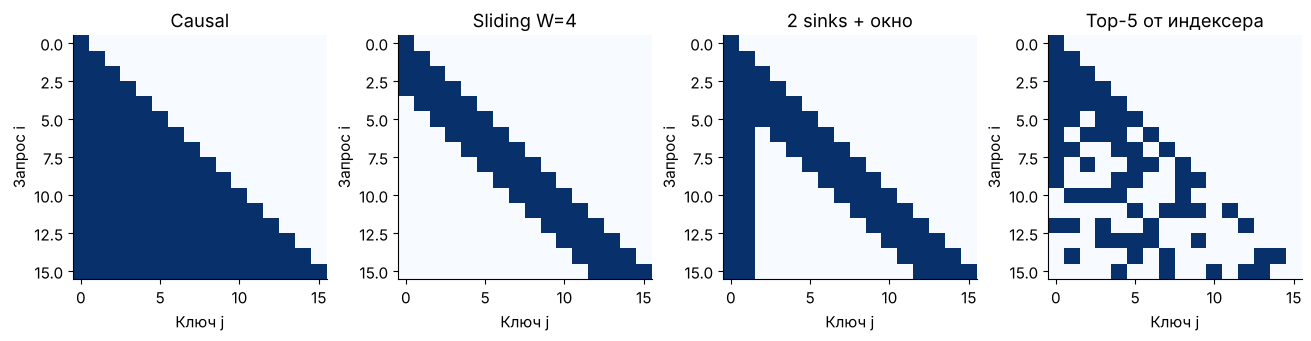

causal     : посчитано 136 scores из 256
sliding    : посчитано  58 scores из 256
sinks+окно : посчитано  81 scores из 256
top-k      : посчитано  70 scores из 256


In [9]:
T_mask, window, sinks, budget = 16, 4, 2, 5
causal_mask = torch.ones(T_mask, T_mask, dtype=torch.bool).tril()
idx = torch.arange(T_mask)
sliding_mask = causal_mask & (idx[:, None] - idx[None, :] < window)
sink_mask = sliding_mask | (causal_mask & (idx[None, :] < sinks))

torch.manual_seed(4)
indexer_scores = torch.randn(T_mask, T_mask).masked_fill(~causal_mask, float("-inf"))
top = indexer_scores.topk(min(budget, T_mask), dim=-1).indices
topk_mask = torch.zeros_like(causal_mask).scatter_(1, top, True) & causal_mask

fig, axes = plt.subplots(1, 4, figsize=(13, 3.3), constrained_layout=True)
for ax, mask, title in zip(axes, [causal_mask, sliding_mask, sink_mask, topk_mask],
                           ["Causal", f"Sliding W={window}", f"{sinks} sinks + окно", f"Top-{budget} от индексера"]):
    heatmap(ax, mask, title, cmap="Blues", vmin=0, vmax=1)
plt.show()
for name, mask in [("causal", causal_mask), ("sliding", sliding_mask), ("sinks+окно", sink_mask), ("top-k", topk_mask)]:
    print(f"{name:11s}: посчитано {int(mask.sum()):3d} scores из {T_mask * T_mask}")

Проверим, как далеко распространяется информация через слои со sliding window.
Если $M$ — булева матрица «кто кого видит» в одном слое, то после $n$ слоёв достижимость задаёт $M^n$.

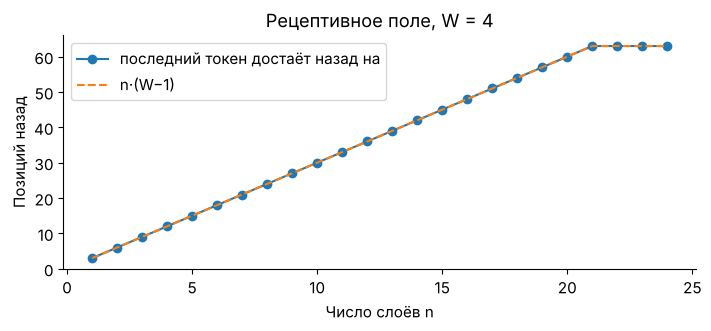

In [10]:
T_reach, window = 64, 4
idx = torch.arange(T_reach)
one_layer = ((idx[:, None] >= idx[None, :]) & (idx[:, None] - idx[None, :] < window)).float()
reach = torch.eye(T_reach)
furthest = []
for n in range(1, 25):
    reach = ((reach @ one_layer) > 0).float()
    visible = reach[-1].nonzero().min().item()          # самый ранний токен, который видит последний
    furthest.append(T_reach - 1 - visible)

fig, ax = plt.subplots(figsize=(7, 3.2), constrained_layout=True)
ax.plot(range(1, 25), furthest, marker="o", label="последний токен достаёт назад на")
ax.plot(range(1, 25), [min(n * (window - 1), T_reach - 1) for n in range(1, 25)], "--", label="n·(W−1)")
ax.set(xlabel="Число слоёв n", ylabel="Позиций назад", title=f"Рецептивное поле, W = {window}")
ax.legend()
plt.show()

Теперь реализуем top-$k$ attention и посмотрим, как ошибка зависит от бюджета $k$.
Здесь в роли индексера выступают сами scores; в реальных моделях это отдельный дешёвый модуль, и он может ошибаться.

In [11]:
def topk_attention(q, k, v, budget):
    scores = (q @ k.transpose(-2, -1)) / math.sqrt(q.shape[-1])
    T = q.shape[-2]
    scores = scores.masked_fill(~torch.ones(T, T, dtype=torch.bool).tril(), float("-inf"))
    budget = min(budget, T)
    threshold = scores.topk(budget, dim=-1).values[..., -1:]      # k-е по величине значение в строке
    sparse_scores = scores.masked_fill(scores < threshold, float("-inf"))
    return sparse_scores.softmax(-1) @ v


torch.manual_seed(5)
T_sparse = 512
q = torch.randn(4, T_sparse, 32) * 2.0   # множитель делает внимание «острее», как у обученных моделей
k = torch.randn(4, T_sparse, 32) * 2.0
v = torch.randn(4, T_sparse, 32)
dense, _ = attention(q, k, v)
budgets = [8, 16, 32, 64, 128, 256, 512]
errors = [((topk_attention(q, k, v, b) - dense).norm() / dense.norm()).item() for b in budgets]
for b, e in zip(budgets, errors):
    print(f"k = {b:3d}: относительная ошибка {e:.3f}")
assert errors[-1] < 1e-5

k =   8: относительная ошибка 0.133
k =  16: относительная ошибка 0.058
k =  32: относительная ошибка 0.023
k =  64: относительная ошибка 0.007
k = 128: относительная ошибка 0.002
k = 256: относительная ошибка 0.000
k = 512: относительная ошибка 0.000


**Вопрос 5.** Sliding window уменьшает размер KV-cache, а top-$k$ sparse attention — нет. Почему? Что тогда экономит sparse attention?

**Вопрос 6.** В модели 32 слоя с окном $W = 4096$. На сколько токенов назад теоретически «видит» последний токен? Почему это не значит, что модель помнит весь этот контекст?

## 5 · Изменение архитектуры или оптимизация реализации
**Зачем:** в статьях и релизах «ускорили attention» может означать две очень разные вещи.

| Тип изменения | Что происходит | Примеры |
|---|---|---|
| **Архитектура** | Меняется функция $f(x)$: другие выходы, нужно обучать или дообучать модель | GQA, MLA, sliding window, sparse attention, слои SSM/DeltaNet |
| **Реализация** | Функция та же (с точностью до округления), меняется порядок вычислений и работа с памятью | FlashAttention, PagedAttention, слияние ядер, continuous batching |
| **Серая зона** | Функция меняется немного, обычно без переобучения | квантование весов и KV-cache (fp8, int4) |

**FlashAttention** не строит матрицу $T \times T$. Он идёт по блокам ключей и поддерживает «онлайн softmax»:
текущий максимум, текущую сумму экспонент и текущий взвешенный выход. Каждый новый блок пересчитывает их, и в конце ответ точно совпадает с обычным attention.
Выигрыш не в FLOPs (их столько же), а в том, что данные почти не ходят между медленной и быстрой памятью GPU.

**PagedAttention** (vLLM) хранит KV-cache страницами, как операционная система хранит виртуальную память. Модель та же,
но память не фрагментируется, и в батч помещается больше запросов.

Реализуем онлайн softmax по блокам и сравним с обычным attention и с `F.scaled_dot_product_attention`.

In [12]:
def blockwise_attention(q, k, v, block=64):
    """Один проход по блокам ключей. Матрица T×T не строится. Causal mask учитывается внутри блока."""
    T, dh = q.shape[-2], q.shape[-1]
    running_max = torch.full(q.shape[:-1] + (1,), float("-inf"))
    running_sum = torch.zeros(q.shape[:-1] + (1,))
    output = torch.zeros_like(q)
    rows = torch.arange(T)[:, None]
    for start in range(0, T, block):
        kb, vb = k[..., start:start + block, :], v[..., start:start + block, :]
        scores = q @ kb.transpose(-2, -1) / math.sqrt(dh)           # [.., T, block] — маленький кусок
        cols = torch.arange(start, start + kb.shape[-2])[None, :]
        scores = scores.masked_fill(cols > rows, float("-inf"))
        new_max = torch.maximum(running_max, scores.amax(-1, keepdim=True))
        correction = torch.exp(running_max - new_max).nan_to_num(0.0)  # старые суммы пересчитываем к новому максимуму
        p = torch.exp(scores - new_max).nan_to_num(0.0)
        running_sum = running_sum * correction + p.sum(-1, keepdim=True)
        output = output * correction + p @ vb
        running_max = new_max
    return output / running_sum


torch.manual_seed(6)
q, k, v = [torch.randn(2, 4, 300, 32) for _ in range(3)]
naive, _ = attention(q, k, v)
torch.testing.assert_close(blockwise_attention(q, k, v), naive, atol=1e-5, rtol=1e-4)
torch.testing.assert_close(F.scaled_dot_product_attention(q, k, v, is_causal=True), naive, atol=1e-5, rtol=1e-4)
print("Блочный attention и PyTorch SDPA совпали с явной формулой.")
print(f"Самый большой промежуточный кусок scores: {300 * 64} чисел вместо {300 * 300} на голову.")

Блочный attention и PyTorch SDPA совпали с явной формулой.
Самый большой промежуточный кусок scores: 19200 чисел вместо 90000 на голову.


**Вопрос 7.** Разложите по трём колонкам таблицы: FlashAttention-3, GQA, PagedAttention, KV-cache в fp8, MLA, sliding window, speculative decoding, слои Mamba.
Для каких из них нужна переобученная модель?

## 6 · Линейное внимание, SSM и Mamba
**Зачем:** KV-cache растёт с длиной. Можно ли хранить прошлое в состоянии **фиксированного** размера, как RNN?

### Линейное внимание
Уберём softmax (в простейшем варианте признаки $q, k$ берём как есть). Тогда выход позиции $t$:

$$o_t = \sum_{j \le t} (q_t^\top k_j)\, v_j = S_t^\top q_t,\qquad S_t = \sum_{j \le t} k_j v_j^\top \in \mathbb R^{d_k \times d_v}.$$

$S_t$ обновляется рекуррентно: $S_t = S_{t-1} + k_t v_t^\top$. На шаге decode нужно $O(1)$ памяти и времени,
независимо от длины контекста. При обучении ту же функцию можно посчитать параллельно: $(QK^\top \odot \text{mask})\,V$.

In [13]:
torch.manual_seed(7)
T_lin, dk, dv = 20, 8, 8
q, k, v = torch.randn(T_lin, dk), torch.randn(T_lin, dk), torch.randn(T_lin, dv)

parallel = ((q @ k.T) * torch.ones(T_lin, T_lin).tril()) @ v      # как при обучении

state = torch.zeros(dk, dv)
recurrent = []
for t in range(T_lin):                                               # как при генерации
    state = state + torch.outer(k[t], v[t])
    recurrent.append(state.T @ q[t])
torch.testing.assert_close(parallel, torch.stack(recurrent), atol=1e-4, rtol=1e-4)
print("Параллельная и рекуррентная формы совпали.")
print(f"Состояние: {dk}×{dv} = {dk * dv} чисел при любой длине; KV-cache на {T_lin} токенах: {2 * T_lin * dk} чисел")

Параллельная и рекуррентная формы совпали.
Состояние: 8×8 = 64 чисел при любой длине; KV-cache на 20 токенах: 320 чисел


### Память фиксированного размера переполняется
$S_t$ — это ассоциативная память: пара $(k, v)$ записывается как $k v^\top$, а чтение по ключу $q$ — это $S^\top q$.
Если просто складывать все пары, они мешают друг другу, и забыть старое нельзя. Исправления:

- **Затухание (gating):** $S_t = \alpha_t S_{t-1} + k_t v_t^\top$, $\alpha_t \in (0, 1)$. Фиксированное $\alpha$ — RetNet, зависящее от входа — GLA, Mamba-2.
- **Delta rule (DeltaNet):** сначала прочитать, что память уже возвращает по этому ключу, и записать только поправку:
  $S_t = S_{t-1} + \beta_t k_t (v_t - S_{t-1}^\top k_t)^\top$. Это шаг градиентного спуска для задачи «по $k_t$ вернуть $v_t$».
- **Gated DeltaNet:** оба механизма вместе: $S_t = \alpha_t (I - \beta_t k_t k_t^\top) S_{t-1} + \beta_t k_t v_t^\top$. Используется в Qwen3-Next и Qwen3.8-Flash-Next.

Два эксперимента. Первый: записываем $n$ разных пар «ключ → значение» и спрашиваем каждый ключ.
Второй: есть 8 «переменных», их значения 200 раз обновляются вперемешку; нужно вернуть последнее значение каждой.

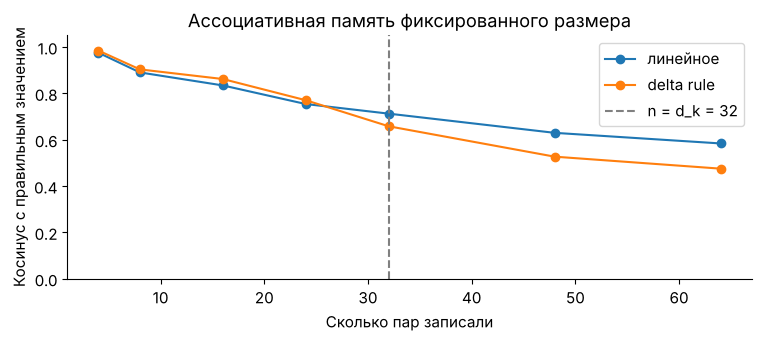

линейное  : косинус с последним значением = 0.17
delta rule: косинус с последним значением = 0.84


In [14]:
def write_linear(keys, values):
    state = torch.zeros(keys.shape[1], values.shape[1])
    for key, value in zip(keys, values):
        state = state + torch.outer(key, value)
    return state


def write_delta(keys, values, beta=1.0):
    state = torch.zeros(keys.shape[1], values.shape[1])
    for key, value in zip(keys, values):
        prediction = state.T @ key
        state = state + beta * torch.outer(key, value - prediction)
    return state


def recall_quality(state, keys, values):
    retrieved = keys @ state                                          # S^T k для каждого ключа
    return F.cosine_similarity(retrieved, values, dim=-1).mean().item()


torch.manual_seed(8)
dim = 32
counts = [4, 8, 16, 24, 32, 48, 64]
results = {"линейное": [], "delta rule": []}
for n in counts:
    keys = F.normalize(torch.randn(n, dim), dim=-1)
    values = torch.randn(n, dim)
    results["линейное"].append(recall_quality(write_linear(keys, values), keys, values))
    results["delta rule"].append(recall_quality(write_delta(keys, values), keys, values))

fig, ax = plt.subplots(figsize=(7.5, 3.3), constrained_layout=True)
for name, values_ in results.items():
    ax.plot(counts, values_, marker="o", label=name)
ax.axvline(dim, color="gray", linestyle="--", label=f"n = d_k = {dim}")
ax.set(xlabel="Сколько пар записали", ylabel="Косинус с правильным значением",
       title="Ассоциативная память фиксированного размера", ylim=(0, 1.05))
ax.legend()
plt.show()

# Обновления: 8 «переменных», значения которых много раз меняются. Нужно помнить последнее значение.
torch.manual_seed(9)
slots, updates = 8, 200
slot_keys = F.normalize(torch.randn(slots, dim), dim=-1)
order = torch.randint(slots, (updates,))
stream_values = torch.randn(updates, dim)
latest = torch.zeros(slots, dim)
for slot, value in zip(order, stream_values):
    latest[slot] = value
for name, writer in [("линейное", write_linear), ("delta rule", write_delta)]:
    state = writer(slot_keys[order], stream_values)
    print(f"{name:10s}: косинус с последним значением = {recall_quality(state, slot_keys, latest):.2f}")

### Где здесь SSM и Mamba
**State Space Model** — линейная рекуррентность из теории управления:

$$h_t = \bar A h_{t-1} + \bar B x_t,\qquad y_t = C h_t.$$

- **S4**: матрицы фиксированы, поэтому всю последовательность можно посчитать как длинную свёртку.
- **Mamba**: $\bar B, C$ и шаг дискретизации $\Delta$ зависят от входа (*selective* SSM): модель сама решает, что запомнить и что забыть.
  Для обучения используется параллельный scan.
- **Mamba-2** показала, что SSM со скалярным затуханием — это линейное внимание с gating. То есть это одно семейство:
  **RNN с матричным состоянием**, которое при обучении считается параллельно.

Сильная сторона: $O(1)$ памяти на шаге decode и линейная стоимость по длине.
Слабая сторона видна в эксперименте выше: состояние конечно, и точно найти один факт из далёкого контекста (номер телефона, строку кода) такой модели трудно.

### Гибриды
Отсюда идея: большинство слоёв сделать линейными, а несколько оставить с полным (или sparse) attention для точного поиска по контексту.
- Jamba: 1 слой attention на 7 слоёв Mamba.
- MiniMax-01: 1 слой softmax attention после каждых 7 слоёв линейного lightning attention.
- Qwen3-Next и Qwen3.8-Flash-Next: 3 слоя Gated DeltaNet на 1 слой attention.

**Вопрос 8.** В первом эксперименте обе памяти теряют точность с ростом $n$, а во втором delta rule сильно выигрывает. Объясните оба результата. Почему гибридные модели всё равно оставляют несколько слоёв полного attention?

## 7 · Разбор: DeepSeek-V3 и Qwen3.8-Flash-Next
**Зачем:** теперь вы можете открыть `config.json` настоящей модели и понять, что из сегодняшнего в ней есть.

**DeepSeek-V3** (декабрь 2024): 671B параметров, из них 37B активны на токен.
61 блок, $d = 7168$, 128 голов. Attention — **MLA**: латент $r = 512$, decoupled RoPE ширины 64,
ширина головы 128 (+64 на RoPE-часть ключа и запроса), запросы тоже сжимаются через ранг 1536.
MLP — MoE (256 экспертов, 8 активных + 1 общий; первые 3 слоя плотные), об этом на следующем занятии.
Контекст 128K. Следующая версия, DeepSeek-V3.2, добавила поверх MLA sparse attention с индексером.

**Qwen3.8-Flash-Next** (август 2026): 125B параметров основной модели, 6B активны на токен.
48 блоков по схеме `12 × (3 × (Gated DeltaNet → MoE) → 1 × (Qwen Sparse Attention → MoE))`, $d = 2560$.
- Gated DeltaNet: 48 голов для $V$, 16 голов для $Q/K$, ширина головы 128.
- Qwen Sparse Attention: 24 головы запросов, 2 головы $K/V$ (GQA), ширина головы 256, RoPE на 64 координаты;
  каждый запрос смотрит на 2048 выбранных токенов, сколько бы ни было контекста.
- MoE: 512 экспертов, 10 + 1 общий активны. Контекст 262 144 токена.

Ключевые поля конфигов и оценка памяти на одну последовательность (bf16). Это **оценка по конфигу**:
реальные движки хранят кэш в fp8, страницами и с дополнительными буферами.

In [15]:
# Значения из официальных конфигов и model card, ссылки в разделе «Источники».
deepseek_v3 = dict(num_hidden_layers=61, hidden_size=7168, num_attention_heads=128,
                   kv_lora_rank=512, qk_rope_head_dim=64, qk_nope_head_dim=128, v_head_dim=128)
qwen38_flash_next = dict(num_hidden_layers=48, full_attention_interval=4, hidden_size=2560,
                         num_attention_heads=24, num_key_value_heads=2, head_dim=256,
                         linear_num_value_heads=48, linear_num_key_heads=16,
                         linear_key_head_dim=128, linear_value_head_dim=128)
BYTES = 2  # bf16


def per_token_mla(cfg):
    return cfg["num_hidden_layers"] * (cfg["kv_lora_rank"] + cfg["qk_rope_head_dim"]) * BYTES


def per_token_mha_equivalent(cfg):
    """Если бы DeepSeek-V3 хранила обычные K и V всех 128 голов."""
    k_dim = cfg["qk_nope_head_dim"] + cfg["qk_rope_head_dim"]
    return cfg["num_hidden_layers"] * cfg["num_attention_heads"] * (k_dim + cfg["v_head_dim"]) * BYTES


def hybrid_memory(cfg, tokens):
    """Растущая часть: K/V только в слоях attention. Фиксированная часть: состояния DeltaNet."""
    attn_layers = cfg["num_hidden_layers"] // cfg["full_attention_interval"]
    linear_layers = cfg["num_hidden_layers"] - attn_layers
    kv = 2 * attn_layers * cfg["num_key_value_heads"] * cfg["head_dim"] * tokens * BYTES
    state = (linear_layers * cfg["linear_num_value_heads"]
             * cfg["linear_key_head_dim"] * cfg["linear_value_head_dim"] * BYTES)
    return kv, state


print("KV-cache на один токен:")
print(f"  Llama-3-8B-подобная (GQA)      : {fmt_bytes(kv_cache_bytes(32, 8, 128, 1))}")
print(f"  DeepSeek-V3, если бы была MHA  : {fmt_bytes(per_token_mha_equivalent(deepseek_v3))}")
print(f"  DeepSeek-V3, MLA               : {fmt_bytes(per_token_mla(deepseek_v3))}")
kv1, state = hybrid_memory(qwen38_flash_next, 1)
print(f"  Qwen3.8-Flash-Next, 12 слоёв QSA: {fmt_bytes(kv1)}  (+ фиксированное состояние DeltaNet {fmt_bytes(state)})")
print(f"\nMLA сжимает кэш DeepSeek-V3 в {per_token_mha_equivalent(deepseek_v3) / per_token_mla(deepseek_v3):.0f} раз по сравнению с MHA.")

KV-cache на один токен:
  Llama-3-8B-подобная (GQA)      : 128.0 KiB
  DeepSeek-V3, если бы была MHA  : 4.8 MiB
  DeepSeek-V3, MLA               : 68.6 KiB
  Qwen3.8-Flash-Next, 12 слоёв QSA: 24.0 KiB  (+ фиксированное состояние DeltaNet 54.0 MiB)

MLA сжимает кэш DeepSeek-V3 в 71 раз по сравнению с MHA.


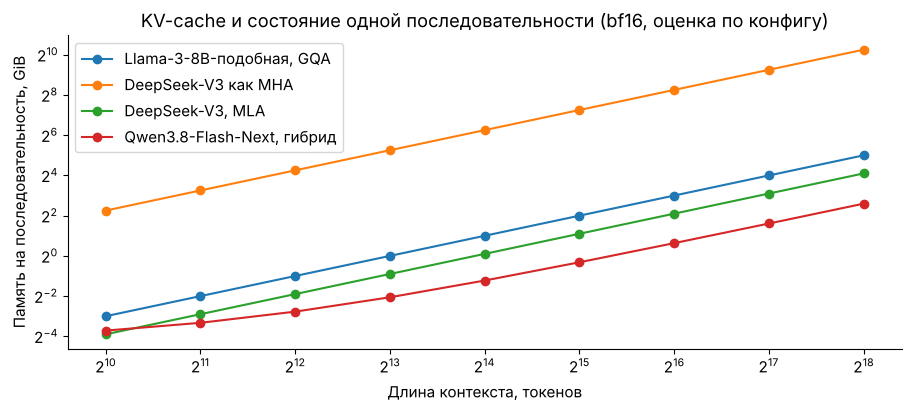

При контексте 131 072 токена:
  Llama-3-8B-подобная, GQA    : 16.0 GiB
  DeepSeek-V3 как MHA         : 610.0 GiB
  DeepSeek-V3, MLA            : 8.6 GiB
  Qwen3.8-Flash-Next, гибрид  : 3.1 GiB


In [16]:
tokens = np.array([2**p for p in range(10, 19)])   # 1K ... 256K
curves = {
    "Llama-3-8B-подобная, GQA": [kv_cache_bytes(32, 8, 128, int(t)) for t in tokens],
    "DeepSeek-V3 как MHA": [per_token_mha_equivalent(deepseek_v3) * t for t in tokens],
    "DeepSeek-V3, MLA": [per_token_mla(deepseek_v3) * t for t in tokens],
    "Qwen3.8-Flash-Next, гибрид": [sum(hybrid_memory(qwen38_flash_next, int(t))) for t in tokens],
}
fig, ax = plt.subplots(figsize=(9, 4), constrained_layout=True)
for name, values in curves.items():
    ax.loglog(tokens, np.array(values) / 2**30, marker="o", label=name, base=2)
ax.set(xlabel="Длина контекста, токенов", ylabel="Память на последовательность, GiB",
       title="KV-cache и состояние одной последовательности (bf16, оценка по конфигу)")
ax.legend()
plt.show()

print("При контексте 131 072 токена:")
for name, values in curves.items():
    print(f"  {name:28s}: {fmt_bytes(values[list(tokens).index(131072)])}")

Цифры на графике — только часть картины. У DeepSeek-V3 веса занимают сотни гигабайт, и кэш на фоне весов небольшой;
у Llama-3-8B на длинном контексте кэш может превысить веса. Скорость тоже зависит не только от памяти:
у sparse attention растёт стоимость индексера, у DeltaNet нужны специальные ядра для параллельного обучения.

**Как читать `config.json` любой модели на Hugging Face:**
- `num_hidden_layers`, `hidden_size`, `num_attention_heads` — базовые размеры;
- `num_key_value_heads` меньше `num_attention_heads` — значит, GQA;
- `kv_lora_rank`, `qk_rope_head_dim` — MLA;
- `sliding_window`, `layer_types`, `full_attention_interval` — какие слои локальные или линейные;
- `max_position_embeddings`, `rope_scaling` — длина контекста и как её растягивали.

**Вопрос 9.** DeepSeek-V3 в 80 с лишним раз больше Llama-3-8B по числу параметров, но кэш на токен у неё меньше. За счёт чего?

**Вопрос 10.** Для Qwen3.8-Flash-Next что занимает больше памяти на контексте 256K: KV-cache слоёв attention или состояния DeltaNet? При какой длине они сравниваются? Проверьте по коду выше.

### Итоги
1. **Стоимость:** attention растёт как $T^2$ по FLOPs; на коротких контекстах дороже MLP и проекции.
2. **KV-cache:** генерация без пересчёта прошлого; decode ограничен чтением памяти.
3. **GQA и MLA:** меньше голов $K/V$ или сжатый латент вместо $K/V$; RoPE в MLA вынесен отдельно.
4. **Sliding window и sparse:** смотрим не на всё; окно экономит кэш, top-$k$ экономит вычисления.
5. **Архитектура и реализация:** FlashAttention и PagedAttention не меняют функцию модели, GQA и MLA меняют.
6. **Линейные модели и SSM:** состояние фиксированного размера, но ограниченная ёмкость; поэтому гибриды.
7. **Реальные модели:** DeepSeek-V3 = MLA + MoE; Qwen3.8-Flash-Next = 3 × Gated DeltaNet + 1 × sparse GQA attention + MoE.

Следующая тема — MoE: почему у DeepSeek-V3 671B параметров, а на токен работает только 37B.

## ★ Дополнительно · задачи для самостоятельной работы
Сначала сформулируйте ответ, потом откройте решение.

**A. Порог $T = 6d$.** Выведите его из таблицы FLOPs в разделе 1. Как изменится порог для модели с GQA, где проекции $K$ и $V$ в 4 раза уже?

<details><summary>Решение</summary>

С GQA проекции стоят $2Td^2$ (Q) $+ 2Td^2$ (O) $+ 2\cdot 2Td^2/4$ (K, V) $= 5Td^2$ вместо $8Td^2$.
Порог: $4T^2d > 21Td^2$, то есть $T > 5.25d$. Квадратичная часть attention от GQA не меняется: запросов столько же.

</details>

**B. Арифметическая интенсивность decode.** Один шаг decode для одного слоя с $H_{kv} = H$: сколько FLOPs и сколько байт KV-cache нужно прочитать для контекста $T$?

<details><summary>Решение</summary>

Scores и взвешивание значений: $\approx 4 T H d_h$ FLOPs. Чтение кэша: $2 T H d_h$ чисел, то есть $4 T H d_h$ байт в bf16.
Около 1 FLOP на байт — в сотни раз меньше, чем может GPU. С GQA байт меньше в $H/H_{kv}$ раз, а FLOPs столько же, поэтому интенсивность растёт.

</details>

**C. Кольцевой буфер.** Измените `CausalSelfAttention` так, чтобы при `window=W` в кэше хранилось не больше $W$ последних ключей. Что нужно учесть про позиции RoPE?

<details><summary>Подсказка</summary>

Обрезайте `cache["k"]` и `cache["v"]` до последних $W$ позиций после конкатенации, но `offset` считайте от общего числа увиденных токенов, а не от длины кэша:
храните счётчик отдельно. Ключи в кэше уже повёрнуты на свои абсолютные позиции, поэтому их можно не пересчитывать.

</details>

**D. Ёмкость состояния.** Покажите, что при попарно ортогональных единичных ключах и $\beta = 1$ обе памяти без ошибок хранят до $d_k$ разных пар. Что меняется, если один и тот же ключ записать дважды?

<details><summary>Решение</summary>

Линейная: $S^\top k_i = \sum_j v_j (k_j^\top k_i) = v_i$, остальные слагаемые обнуляются. Delta rule: после записи $(k, v)$ память возвращает по $k$ ровно $v$,
а следующие записи меняют $S$ только вдоль новых ключей, ортогональных $k$. Ортогональных направлений в $\mathbb R^{d_k}$ ровно $d_k$, дальше ключи неизбежно мешают друг другу.
При повторной записи ключа линейная память вернёт $v_1 + v_2$, а delta rule сначала вычтет $v_1$ и вернёт $v_2$.

</details>

## Источники
- [Attention Is All You Need](https://arxiv.org/abs/1706.03762)
- [MQA: Fast Transformer Decoding](https://arxiv.org/abs/1911.02150) и [GQA](https://arxiv.org/abs/2305.13245)
- [DeepSeek-V2: MLA](https://arxiv.org/abs/2405.04434) и [DeepSeek-V3 Technical Report](https://arxiv.org/abs/2412.19437)
- [Longformer](https://arxiv.org/abs/2004.05150), [Mistral 7B](https://arxiv.org/abs/2310.06825), [StreamingLLM: attention sinks](https://arxiv.org/abs/2309.17453)
- [Native Sparse Attention](https://arxiv.org/abs/2502.11089)
- [FlashAttention](https://arxiv.org/abs/2205.14135) и [PagedAttention / vLLM](https://arxiv.org/abs/2309.06180)
- [Linear Transformers are RNNs](https://arxiv.org/abs/2006.16236), [Mamba](https://arxiv.org/abs/2312.00752), [Mamba-2](https://arxiv.org/abs/2405.21060)
- [DeltaNet: parallelizing linear transformers with the delta rule](https://arxiv.org/abs/2406.06484) и [Gated DeltaNet](https://arxiv.org/abs/2412.06464)
- [Jamba](https://arxiv.org/abs/2403.19887), [MiniMax-01](https://arxiv.org/abs/2501.08313)
- [Qwen3-Next-80B-A3B model card](https://huggingface.co/Qwen/Qwen3-Next-80B-A3B-Thinking)
- [Qwen3.8-Flash-Next: репозиторий](https://github.com/QwenLM/Qwen3.8-Flash-Next/) и [технический отчёт](https://arxiv.org/abs/2608.30320)

**Упрощения:** все замеры на CPU и маленьких размерах; блочный attention показывает идею FlashAttention, но не его скорость;
DeltaNet реализован последовательным циклом без параллельного chunked-алгоритма; оценки памяти не учитывают
состояния свёрток, индексер sparse attention, fp8-хранение и служебные буферы движков.